| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week10** | Computer Vision                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | November 25, 2026, 11:55 PM                                                                                                                                                                                                                                                                                          |
| **Student Name** - Number  & Kaggle Username     | Edward Chisaka - 1774058: siredwardchisaka                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week10_ Lab implementation exercise.<br/> **__COMPUTER VISION__**.<br/> _Digit Recognizer_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/10-assignment) ||

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Libraries

In [2]:
import os
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


## Load the Data

In [3]:
def locate_file(filename):
    candidate_paths = [
        Path("/kaggle/input/digit-recognizer") / filename,
        Path("/kaggle/input") / filename,
        Path("data") / filename,
        Path("dataset") / filename,
        Path(filename),
    ]

    for path in candidate_paths:
        if path.exists():
            return path

    # Search Kaggle's mounted competition folders.
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        matches = list(kaggle_input.rglob(filename))
        if matches:
            return matches[0]

    raise FileNotFoundError(
        f"Could not find {filename}. Add the Digit Recognizer competition "
        "data to Kaggle, or place the file in ./data/."
    )

TRAIN_PATH = locate_file("train.csv")
TEST_PATH = locate_file("test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
display(train_df.head())

Training data: (42000, 785)
Test data: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## EDA - Exploratory Data Analysis

In [4]:
print("Training information:")
train_df.info()

print("\nMissing values in training data:", int(train_df.isna().sum().sum()))
print("Missing values in test data:", int(test_df.isna().sum().sum()))
print("Duplicate training rows:", int(train_df.duplicated().sum()))
print("Duplicate test rows:", int(test_df.duplicated().sum()))

print("\nTarget distribution:")
display(train_df["label"].value_counts().sort_index().to_frame("count"))

pixel_columns = [c for c in train_df.columns if c != "label"]
print("\nNumber of pixel features:", len(pixel_columns))
print("Training pixel range:", train_df[pixel_columns].to_numpy().min(),
      "to", train_df[pixel_columns].to_numpy().max())
print("Test pixel range:", test_df.to_numpy().min(), "to", test_df.to_numpy().max())

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB

Missing values in training data: 0
Missing values in test data: 0
Duplicate training rows: 0
Duplicate test rows: 0

Target distribution:


,count
label,
0,4132
1,4684
2,4177
3,4351
4,4072
5,3795
6,4137
7,4401
8,4063



Number of pixel features: 784
Training pixel range: 0 to 255
Test pixel range: 0 to 255


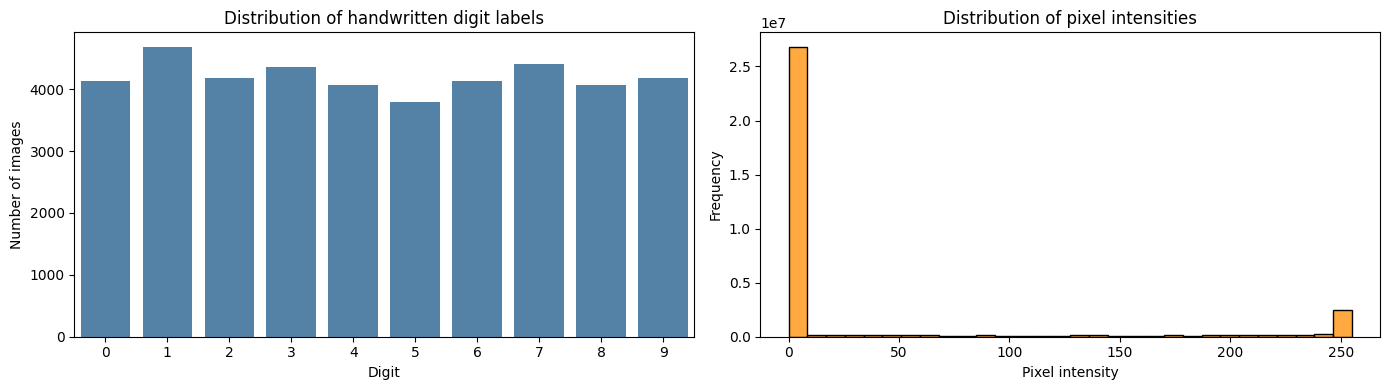

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(x=train_df["label"], ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of handwritten digit labels")
axes[0].set_xlabel("Digit")
axes[0].set_ylabel("Number of images")

sns.histplot(
    train_df[pixel_columns].to_numpy().ravel(),
    bins=30, ax=axes[1], color="darkorange"
)
axes[1].set_title("Distribution of pixel intensities")
axes[1].set_xlabel("Pixel intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

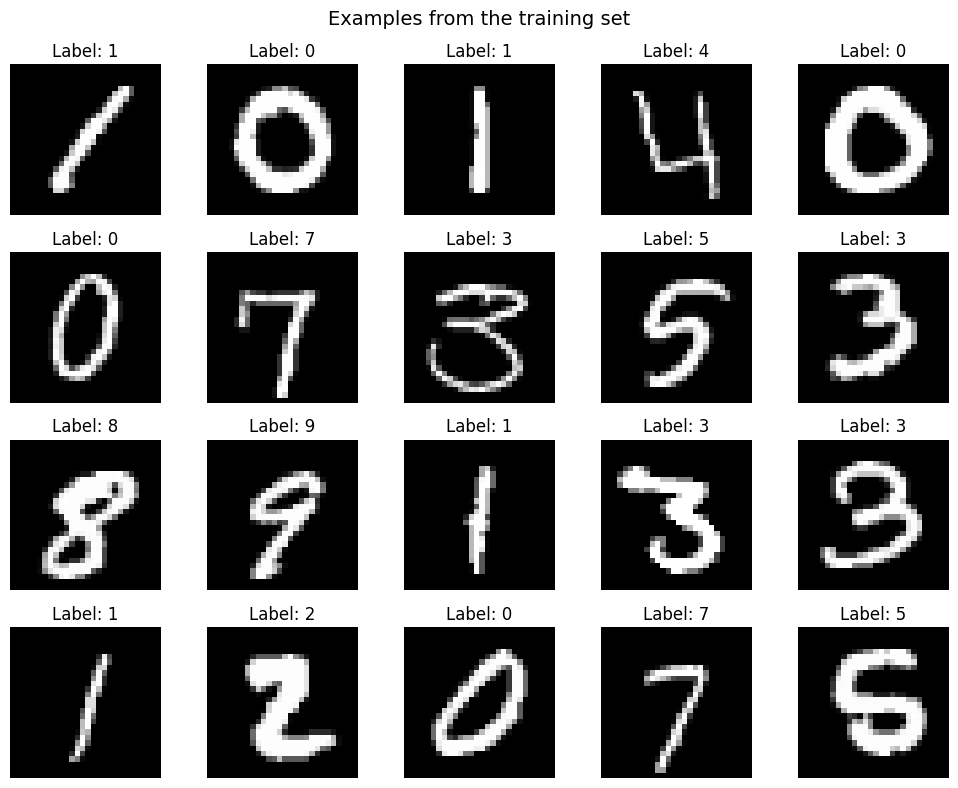

In [6]:
X_all = train_df.drop(columns="label").to_numpy(dtype=np.float32)
y_all = train_df["label"].to_numpy(dtype=np.int64)
X_test_raw = test_df.to_numpy(dtype=np.float32)

def show_digit_grid(images, labels=None, n=20, columns=5, title="Sample digits"):
    n = min(n, len(images))
    rows = int(np.ceil(n / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 2, rows * 2))
    axes = np.array(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")
        if i < n:
            axes[i].imshow(images[i].reshape(28, 28), cmap="gray")
            if labels is not None:
                axes[i].set_title(f"Label: {labels[i]}")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_digit_grid(X_all, y_all, n=20, title="Examples from the training set")

## Data Preparation

In [7]:
X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all
)

X_train = X_train_raw / 255.0
X_valid = X_valid_raw / 255.0
X_test = X_test_raw / 255.0

X_train_img = X_train.reshape(-1, 28, 28, 1)
X_valid_img = X_valid.reshape(-1, 28, 28, 1)
X_test_img = X_test.reshape(-1, 28, 28, 1)

print("Training split:", X_train.shape)
print("Validation split:", X_valid.shape)
print("Test set:", X_test.shape)
print("Image tensor:", X_train_img.shape)

Training split: (33600, 784)
Validation split: (8400, 784)
Test set: (28000, 784)
Image tensor: (33600, 28, 28, 1)


# Machine Learning Algorithms

## Logistic Regression Baseline

In [8]:
results = []
trained_models = {}

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1200,
        solver="lbfgs",
        C=3.0,
        random_state=SEED
    ))
])

log_reg.fit(X_train, y_train)
pred_log = log_reg.predict(X_valid)
acc_log = accuracy_score(y_valid, pred_log)

trained_models["Logistic Regression"] = log_reg
results.append({"Model": "Logistic Regression", "Validation Accuracy": acc_log})

print(f"Logistic Regression accuracy: {acc_log:.5f}")

Logistic Regression accuracy: 0.89702


## Random Forest

In [9]:
random_forest = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=SEED
)

random_forest.fit(X_train_raw, y_train)
pred_rf = random_forest.predict(X_valid_raw)
acc_rf = accuracy_score(y_valid, pred_rf)

trained_models["Random Forest"] = random_forest
results.append({"Model": "Random Forest", "Validation Accuracy": acc_rf})

print(f"Random Forest accuracy: {acc_rf:.5f}")

Random Forest accuracy: 0.96667


## Extremely Randomized Trees (Extra Trees)

In [10]:
extra_trees = ExtraTreesClassifier(
    n_estimators=400,
    max_features="sqrt",
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=SEED
)

extra_trees.fit(X_train_raw, y_train)
pred_et = extra_trees.predict(X_valid_raw)
acc_et = accuracy_score(y_valid, pred_et)

trained_models["Extra Trees"] = extra_trees
results.append({"Model": "Extra Trees", "Validation Accuracy": acc_et})

print(f"Extra Trees accuracy: {acc_et:.5f}")

Extra Trees accuracy: 0.97024


## Support Vector Machine (RBF kernel)

In [11]:
RUN_SVM = True
SVM_MAX_TRAIN_ROWS = 18000  # Set to None to use the full training split.

if RUN_SVM:
    if SVM_MAX_TRAIN_ROWS is not None and SVM_MAX_TRAIN_ROWS < len(X_train):
        X_svm, _, y_svm, _ = train_test_split(
            X_train, y_train,
            train_size=SVM_MAX_TRAIN_ROWS,
            random_state=SEED,
            stratify=y_train
        )
    else:
        X_svm, y_svm = X_train, y_train

    svm_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            C=8.0,
            kernel="rbf",
            gamma="scale",
            cache_size=1500
        ))
    ])

    svm_model.fit(X_svm, y_svm)
    pred_svm = svm_model.predict(X_valid)
    acc_svm = accuracy_score(y_valid, pred_svm)

    trained_models["RBF SVM"] = svm_model
    results.append({"Model": "RBF SVM", "Validation Accuracy": acc_svm})
    print(f"RBF SVM accuracy: {acc_svm:.5f}")
else:
    print("SVM skipped.")

RBF SVM accuracy: 0.95536


# Neural Networks (NN)

## Multilayer Perceptron (MLP)

In [12]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(512, 256),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=256,
    learning_rate_init=1e-3,
    max_iter=35,
    early_stopping=True,
    validation_fraction=0.12,
    n_iter_no_change=5,
    random_state=SEED,
    verbose=True
)

mlp_model.fit(X_train, y_train)
pred_mlp = mlp_model.predict(X_valid)
acc_mlp = accuracy_score(y_valid, pred_mlp)

trained_models["MLP Neural Network"] = mlp_model
results.append({"Model": "MLP Neural Network", "Validation Accuracy": acc_mlp})

print(f"MLP accuracy: {acc_mlp:.5f}")

Iteration 1, loss = 0.39649620
Validation score: 0.950149
Iteration 2, loss = 0.14312106
Validation score: 0.962798
Iteration 3, loss = 0.08715832
Validation score: 0.963294
Iteration 4, loss = 0.06023453
Validation score: 0.963046
Iteration 5, loss = 0.04303977
Validation score: 0.970238
Iteration 6, loss = 0.03057536
Validation score: 0.970982
Iteration 7, loss = 0.02090784
Validation score: 0.969990
Iteration 8, loss = 0.01444172
Validation score: 0.974454
Iteration 9, loss = 0.00972694
Validation score: 0.972718
Iteration 10, loss = 0.00756013
Validation score: 0.970238
Iteration 11, loss = 0.00701270
Validation score: 0.974950
Iteration 12, loss = 0.00811826
Validation score: 0.970982
Iteration 13, loss = 0.00479078
Validation score: 0.974454
Iteration 14, loss = 0.00210006
Validation score: 0.977183
Iteration 15, loss = 0.00107396
Validation score: 0.976190
Iteration 16, loss = 0.00082758
Validation score: 0.975942
Iteration 17, loss = 0.00072248
Validation score: 0.976438
Iterat

## Convolutional Neural Network (CNN)

In [13]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    TF_AVAILABLE = True
    tf.keras.utils.set_random_seed(SEED)
    print("TensorFlow:", tf.__version__)
except Exception as error:
    TF_AVAILABLE = False
    print("TensorFlow is unavailable; CNN section will be skipped.")
    print("Reason:", error)

TensorFlow: 2.21.0


In [14]:
cnn_model = None
cnn_history = None
acc_cnn = None
pred_cnn = None

if TF_AVAILABLE:
    cnn_model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.35),
        layers.Dense(10, activation="softmax")
    ])

    cnn_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    cnn_model.summary()

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=4,
            restore_best_weights=True,
            mode="max"
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ]

    cnn_history = cnn_model.fit(
        X_train_img, y_train,
        validation_data=(X_valid_img, y_valid),
        epochs=20,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    valid_probabilities = cnn_model.predict(X_valid_img, verbose=0)
    pred_cnn = np.argmax(valid_probabilities, axis=1)
    acc_cnn = accuracy_score(y_valid, pred_cnn)

    results.append({"Model": "CNN", "Validation Accuracy": acc_cnn})
    print(f"CNN accuracy: {acc_cnn:.5f}")
else:
    print("CNN skipped because TensorFlow is not installed.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,906 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 37s 78ms/step - accuracy: 0.9301 - loss: 0.2298 - val_accuracy: 0.1115 - val_loss: 5.3558 - learning_rate: 0.0010
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9786 - loss: 0.0708 - val_accuracy: 0.9317 - val_loss: 0.2368 - learning_rate: 0.0010
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9841 - loss: 0.0529 - val_accuracy: 0.9871 - val_loss: 0.0418 - learning_rate: 0.0010
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9870 - loss: 0.0421 - val_accuracy: 0.9833 - val_loss: 0.0514 - learning_rate: 0.0010
Epoch 5/20
259/263 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9878 - loss: 0.0383
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9882 - loss: 0.0376 - val_accuracy: 0.9852 - val_loss: 0.0498 - learning_rate: 0.0010
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9911 - loss: 0.0

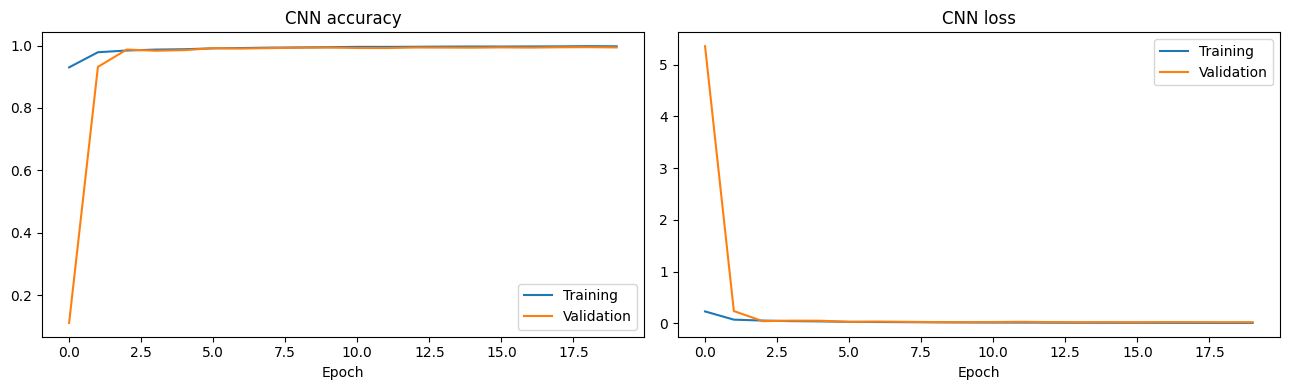

In [15]:
if TF_AVAILABLE and cnn_history is not None:
    history_df = pd.DataFrame(cnn_history.history)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history_df["accuracy"], label="Training")
    axes[0].plot(history_df["val_accuracy"], label="Validation")
    axes[0].set_title("CNN accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history_df["loss"], label="Training")
    axes[1].plot(history_df["val_loss"], label="Validation")
    axes[1].set_title("CNN loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# Transfer Learning, Vision Transformers and Explainable AI

In [16]:

# PyTorch setup for transfer learning and Vision Transformers
import time
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Adjust these settings based on the available Kaggle accelerator.
RESNET_EPOCHS = 7
VIT_EPOCHS = 18
DEEP_BATCH_SIZE = 128
NUM_WORKERS = 2


PyTorch: 2.14.1+cu130
Device: cuda


## Transfer Learning with Pretrained ResNet18

In [17]:

import gc
import copy
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import accuracy_score


# ============================================================
# 1. INITIALIZE RESULT CONTAINERS
# ============================================================

if "results" not in globals():
    results = []

if "trained_models" not in globals():
    trained_models = {}


# ============================================================
# 2. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=DEVICE
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=DEVICE
).view(1, 3, 1, 1)


# ============================================================
# 3. PREPARE COMPACT IMAGE TENSORS
# ============================================================

def prepare_compact_images(x_numpy):
    """
    Store images compactly in system RAM.
    Shape: N x 1 x 28 x 28
    """
    return (
        torch.tensor(x_numpy, dtype=torch.float32)
        .view(-1, 1, 28, 28) / 255.0
    )


def preprocess_resnet_batch(xb):
    """
    Convert grayscale images into normalized RGB images.
    Resize to 96 x 96.
    """
    xb = xb.to(DEVICE, non_blocking=True)

    # Convert grayscale to 3 channels
    xb = xb.repeat(1, 3, 1, 1)

    # Resize images
    xb = F.interpolate(
        xb,
        size=(96, 96),
        mode="bilinear",
        align_corners=False
    )

    # ImageNet normalization
    xb = (xb - IMAGENET_MEAN) / IMAGENET_STD

    return xb


# Prepare datasets
X_train_res = prepare_compact_images(X_train_raw)
X_valid_res = prepare_compact_images(X_valid_raw)
X_test_res = prepare_compact_images(X_test_raw)


# ============================================================
# 4. CREATE DATA LOADERS
# ============================================================

def make_loader(
    x,
    y=None,
    batch_size=DEEP_BATCH_SIZE,
    shuffle=False
):
    if y is None:
        ds = TensorDataset(x)
    else:
        y_tensor = torch.tensor(
            y,
            dtype=torch.long
        )
        ds = TensorDataset(x, y_tensor)

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


train_res_loader = make_loader(
    X_train_res,
    y_train,
    shuffle=True
)

valid_res_loader = make_loader(
    X_valid_res,
    y_valid
)

test_res_loader = make_loader(
    X_test_res
)


# ============================================================
# 5. LOAD PRETRAINED RESNET18
# ============================================================

try:
    resnet_weights = ResNet18_Weights.DEFAULT

    resnet_model = resnet18(
        weights=resnet_weights
    )

    RESNET_PRETRAINED = True

    print("Loaded pretrained ImageNet ResNet18 weights.")

except Exception as error:

    print(
        "Could not load ImageNet weights:",
        repr(error)
    )

    print(
        "Falling back to randomly initialized ResNet18."
    )

    resnet_model = resnet18(weights=None)

    RESNET_PRETRAINED = False


# Replace final classification layer with 10 classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    10
)

resnet_model = resnet_model.to(DEVICE)


# ============================================================
# 6. FREEZE AND UNFREEZE MODEL LAYERS
# ============================================================

# Freeze all parameters
for parameter in resnet_model.parameters():
    parameter.requires_grad = False

# Fine-tune final residual stage
for parameter in resnet_model.layer4.parameters():
    parameter.requires_grad = True

# Train the new classification layer
for parameter in resnet_model.fc.parameters():
    parameter.requires_grad = True


# ============================================================
# 7. TRAINING FUNCTION WITH EARLY STOPPING
# ============================================================

def train_torch_classifier(
    model,
    train_loader,
    valid_loader,
    epochs,
    lr,
    trainable_parameters=None,
    patience=4,
    batch_transform=None
):

    if trainable_parameters is None:
        trainable_parameters = [
            p for p in model.parameters()
            if p.requires_grad
        ]

    optimizer = torch.optim.AdamW(
        trainable_parameters,
        lr=lr,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    best_state = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    stale = 0

    history = []

    start = time.time()

    for epoch in range(1, epochs + 1):

        # ---------------- TRAINING ----------------

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in train_loader:

            xb = (
                batch_transform(xb)
                if batch_transform is not None
                else xb.to(DEVICE)
            )

            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(xb)

            loss = criterion(logits, yb)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * len(yb)

            correct += (
                logits.argmax(1) == yb
            ).sum().item()

            total += len(yb)

        # ---------------- VALIDATION ----------------

        model.eval()

        val_correct = 0
        val_total = 0
        val_loss = 0.0

        with torch.no_grad():

            for xb, yb in valid_loader:

                xb = (
                    batch_transform(xb)
                    if batch_transform is not None
                    else xb.to(DEVICE)
                )

                yb = yb.to(DEVICE)

                logits = model(xb)

                loss = criterion(logits, yb)

                val_loss += loss.item() * len(yb)

                val_correct += (
                    logits.argmax(1) == yb
                ).sum().item()

                val_total += len(yb)

        train_acc = correct / total
        val_acc = val_correct / val_total

        history.append({
            "epoch": epoch,
            "train_loss": running_loss / total,
            "train_accuracy": train_acc,
            "val_loss": val_loss / val_total,
            "val_accuracy": val_acc
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train acc {train_acc:.4f} | "
            f"val acc {val_acc:.4f}"
        )

        # ---------------- EARLY STOPPING ----------------

        if val_acc > best_acc:

            best_acc = val_acc

            best_state = copy.deepcopy(
                model.state_dict()
            )

            stale = 0

        else:

            stale += 1

            if stale >= patience:

                print("Early stopping.")

                break

    # Restore best model
    model.load_state_dict(best_state)

    return (
        model,
        pd.DataFrame(history),
        best_acc,
        time.time() - start
    )


# ============================================================
# 8. PREDICTION FUNCTION
# ============================================================

def torch_predict(
    model,
    loader,
    batch_transform=None
):

    model.eval()

    outputs = []

    with torch.no_grad():

        for batch in loader:

            # FIX: Extract tensor from TensorDataset batch
            xb = (
                batch[0]
                if isinstance(batch, (list, tuple))
                else batch
            )

            xb = (
                batch_transform(xb)
                if batch_transform is not None
                else xb.to(DEVICE)
            )

            logits = model(xb)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            outputs.append(
                probabilities.cpu().numpy()
            )

    return np.concatenate(outputs, axis=0)


# ============================================================
# 9. TRAIN RESNET18
# ============================================================

resnet_model, resnet_history, acc_resnet, time_resnet = (
    train_torch_classifier(
        resnet_model,
        train_res_loader,
        valid_res_loader,
        epochs=RESNET_EPOCHS,
        lr=2e-4,
        patience=3,
        batch_transform=preprocess_resnet_batch
    )
)


# ============================================================
# 10. VALIDATION PREDICTIONS
# ============================================================

prob_resnet = torch_predict(
    resnet_model,
    valid_res_loader,
    batch_transform=preprocess_resnet_batch
)

pred_resnet = prob_resnet.argmax(axis=1)


# ============================================================
# 11. EVALUATE MODEL
# ============================================================

resnet_accuracy = accuracy_score(
    y_valid,
    pred_resnet
)

# Store results
results.append({
    "Model": (
        "Pretrained ResNet18"
        if RESNET_PRETRAINED
        else "ResNet18 (unpretrained fallback)"
    ),
    "Validation Accuracy": resnet_accuracy
})

# Store trained model
trained_models["ResNet18"] = resnet_model

print("\n========== RESNET18 RESULTS ==========")

print(
    "ResNet18 validation accuracy:",
    round(resnet_accuracy, 4)
)

print(
    "ResNet18 training time (seconds):",
    round(time_resnet, 1)
)


# ============================================================
# 12. DISPLAY TRAINING HISTORY
# ============================================================

print("\nResNet18 Training History:")

display(resnet_history)


# ============================================================
# 13. FREE TEMPORARY TENSORS
# ============================================================

del X_train_res
del X_valid_res
del X_test_res

gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


print("\nResNet18 training and evaluation completed successfully.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


Loaded pretrained ImageNet ResNet18 weights.
Epoch 01/7 | train acc 0.9654 | val acc 0.9874
Epoch 02/7 | train acc 0.9939 | val acc 0.9844
Epoch 03/7 | train acc 0.9968 | val acc 0.9874
Epoch 04/7 | train acc 0.9982 | val acc 0.9870
Early stopping.

========== RESNET18 RESULTS ==========
ResNet18 validation accuracy: 0.9874
ResNet18 training time (seconds): 44.0

ResNet18 Training History:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.115624,0.965357,0.045940,0.987381
1,2,0.020164,0.993929,0.048527,0.984405
2,3,0.009981,0.996756,0.046779,0.987381
3,4,0.006466,0.998185,0.043999,0.987024



ResNet18 training and evaluation completed successfully.


## Vision Transformer (ViT)

Epoch 01/18 | train acc 0.5151 | val acc 0.8174
Epoch 02/18 | train acc 0.8494 | val acc 0.9090
Epoch 03/18 | train acc 0.9029 | val acc 0.9280
Epoch 04/18 | train acc 0.9274 | val acc 0.9438
Epoch 05/18 | train acc 0.9398 | val acc 0.9504
Epoch 06/18 | train acc 0.9514 | val acc 0.9521
Epoch 07/18 | train acc 0.9559 | val acc 0.9590
Epoch 08/18 | train acc 0.9632 | val acc 0.9612
Epoch 09/18 | train acc 0.9653 | val acc 0.9692
Epoch 10/18 | train acc 0.9681 | val acc 0.9706
Epoch 11/18 | train acc 0.9710 | val acc 0.9732
Epoch 12/18 | train acc 0.9747 | val acc 0.9713
Epoch 13/18 | train acc 0.9762 | val acc 0.9690
Epoch 14/18 | train acc 0.9771 | val acc 0.9708
Epoch 15/18 | train acc 0.9796 | val acc 0.9714
Epoch 16/18 | train acc 0.9786 | val acc 0.9773
Epoch 17/18 | train acc 0.9808 | val acc 0.9745
Epoch 18/18 | train acc 0.9820 | val acc 0.9745
ViT validation accuracy: 0.9772619047619048
ViT training time (seconds): 101.7


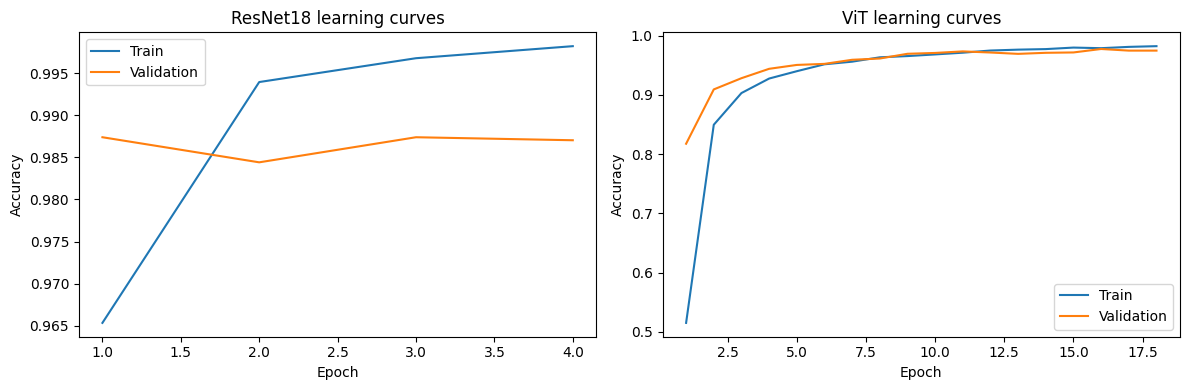

In [18]:
import gc

class TransformerEncoderBlock(nn.Module):
    def __init__(self, dim=128, heads=4, mlp_dim=256, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(
            dim, heads, dropout=dropout, batch_first=True
        )
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(mlp_dim, dim), nn.Dropout(dropout)
        )

    def forward(self, x, return_attention=False):
        normalized = self.norm1(x)
        attended, weights = self.attn(
            normalized, normalized, normalized,
            need_weights=return_attention,
            average_attn_weights=False
        )
        x = x + attended
        x = x + self.mlp(self.norm2(x))
        if return_attention:
            return x, weights
        return x

class DigitViT(nn.Module):
    def __init__(self, image_size=28, patch_size=4, dim=128,
                 depth=4, heads=4, num_classes=10, dropout=0.1):
        super().__init__()
        assert image_size % patch_size == 0
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(
            1, dim, kernel_size=patch_size, stride=patch_size
        )
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, dim))
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(dim, heads, dim * 2, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x, return_attention=False):
        # x: batch x 1 x 28 x 28
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = self.dropout(torch.cat([cls, x], dim=1) + self.pos_embed)
        attentions = []
        for block in self.blocks:
            if return_attention:
                x, weights = block(x, return_attention=True)
                attentions.append(weights)
            else:
                x = block(x)
        x = self.norm(x)
        logits = self.head(x[:, 0])
        if return_attention:
            return logits, attentions
        return logits

def prepare_vit_images(x_numpy):
    return torch.tensor(x_numpy, dtype=torch.float32).view(-1, 1, 28, 28) / 255.0

X_train_vit = prepare_vit_images(X_train_raw)
X_valid_vit = prepare_vit_images(X_valid_raw)
X_test_vit = prepare_vit_images(X_test_raw)

train_vit_loader = make_loader(X_train_vit, y_train, shuffle=True)
valid_vit_loader = make_loader(X_valid_vit, y_valid)
test_vit_loader = make_loader(X_test_vit)

vit_model = DigitViT().to(DEVICE)
vit_model, vit_history, acc_vit, time_vit = train_torch_classifier(
    vit_model, train_vit_loader, valid_vit_loader,
    epochs=VIT_EPOCHS, lr=5e-4, patience=5
)
prob_vit = torch_predict(vit_model, valid_vit_loader)
pred_vit = prob_vit.argmax(axis=1)

results.append({
    "Model": "Vision Transformer (ViT)",
    "Validation Accuracy": accuracy_score(y_valid, pred_vit)
})
trained_models["Vision Transformer (ViT)"] = vit_model
print("ViT validation accuracy:", accuracy_score(y_valid, pred_vit))
print("ViT training time (seconds):", round(time_vit, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resnet_history["epoch"], resnet_history["train_accuracy"], label="Train")
axes[0].plot(resnet_history["epoch"], resnet_history["val_accuracy"], label="Validation")
axes[0].set_title("ResNet18 learning curves")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].plot(vit_history["epoch"], vit_history["train_accuracy"], label="Train")
axes[1].plot(vit_history["epoch"], vit_history["val_accuracy"], label="Validation")
axes[1].set_title("ViT learning curves")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

# Free temporary tensors (keep test_vit_loader if needed for test predictions later)
del X_train_vit, X_valid_vit
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## Explainable AI - XAI: Which image features influence predictions?

- Input saliency: gradient magnitude with respect to input pixels.

- Grad-CAM: activation regions in the final ResNet convolutional block that support a selected class.

- ViT attention rollout: approximate patch importance by combining attention across transformer blocks.

Selected validation indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(121), np.int64(242), np.int64(400)]


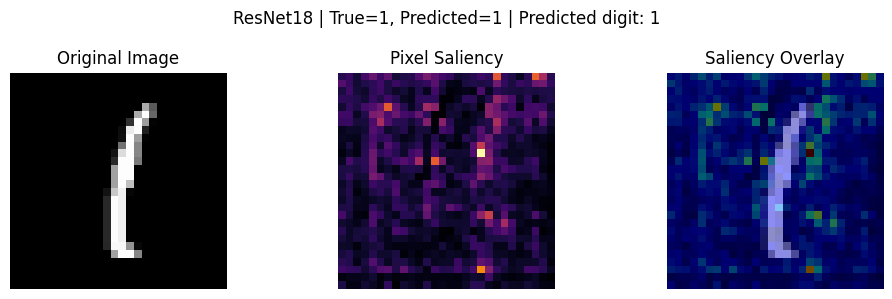

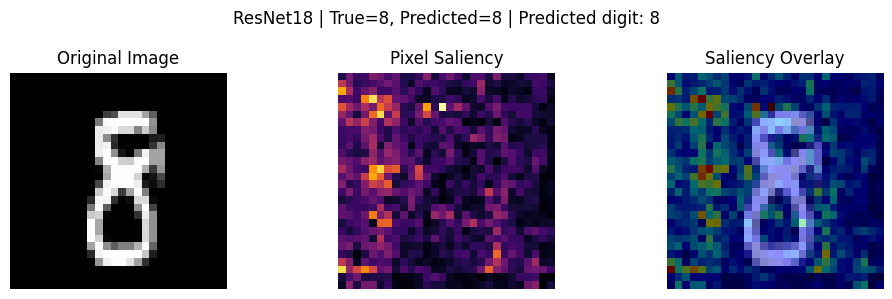

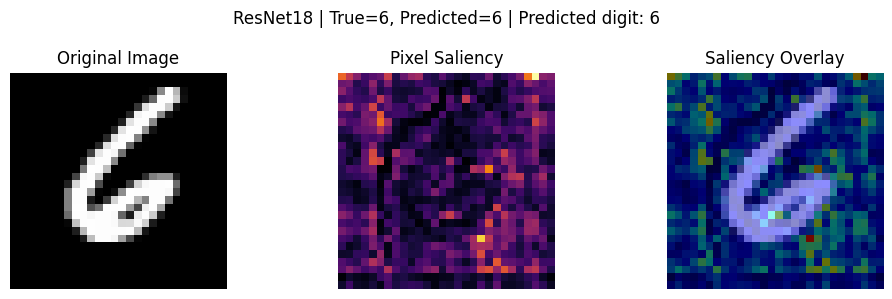

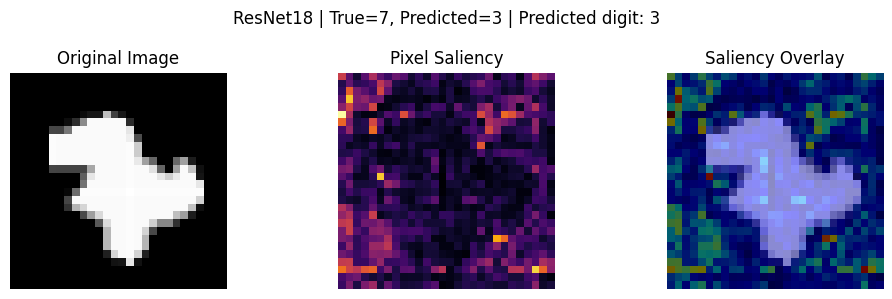

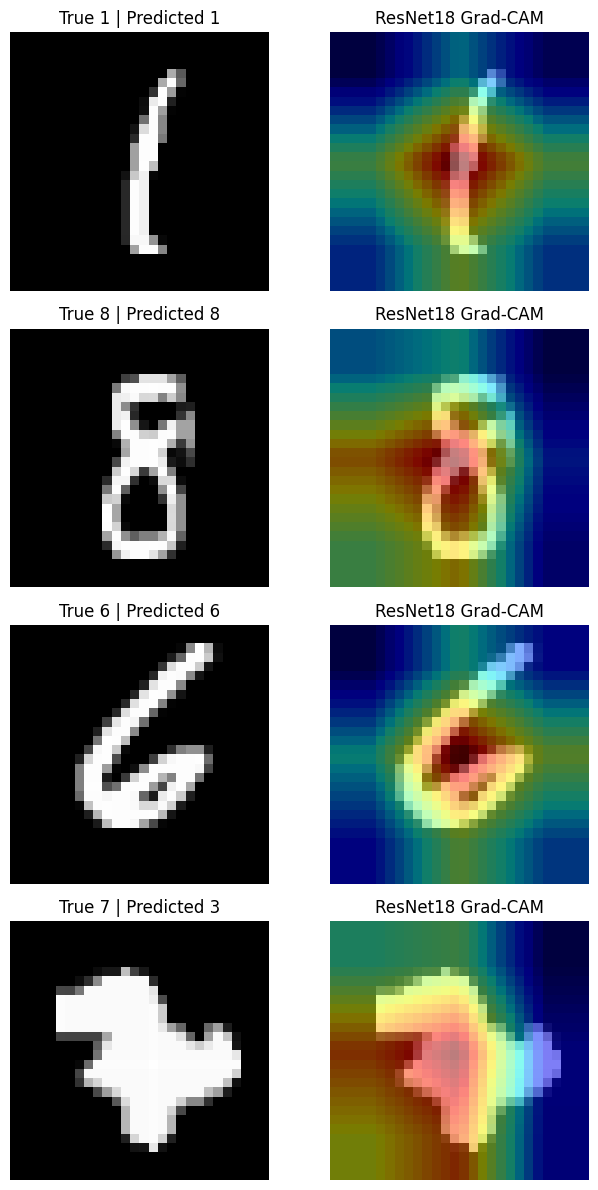

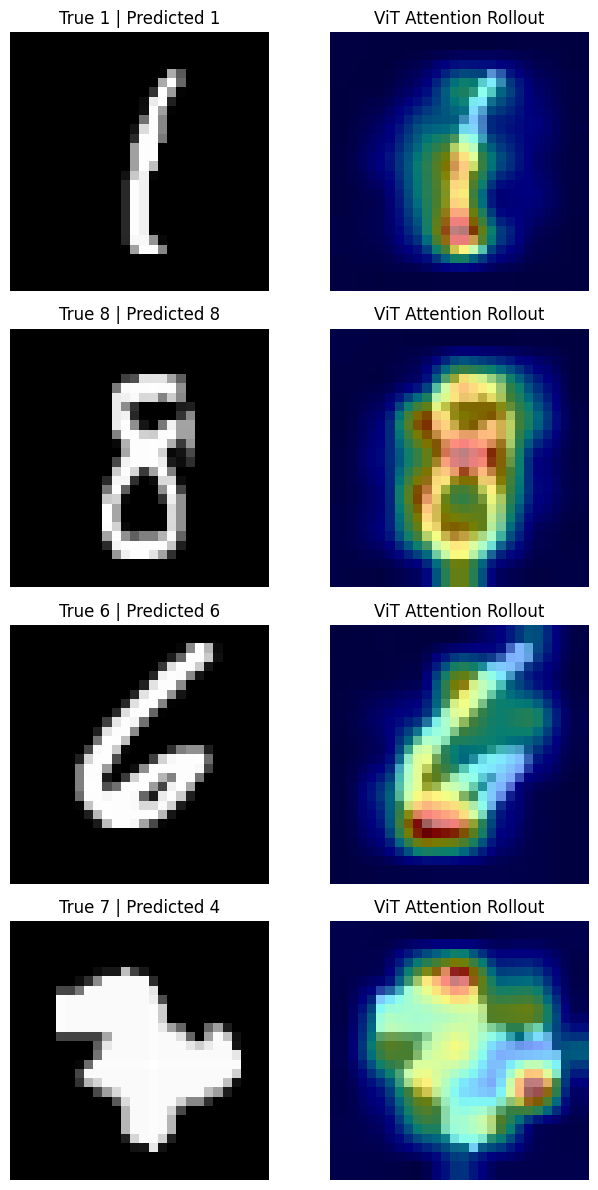


XAI analysis completed successfully.
ResNet18 methods:
- Input Pixel Saliency
- Grad-CAM

ViT methods:
- Attention Rollout


In [19]:

# ============================================================
# 1. SELECT CORRECTLY AND INCORRECTLY CLASSIFIED EXAMPLES
# ============================================================

resnet_errors = np.where(pred_resnet != y_valid)[0]
resnet_correct = np.where(pred_resnet == y_valid)[0]

selected_xai = (
    list(resnet_correct[:3]) +
    list(resnet_errors[:3])
)

if len(selected_xai) == 0:
    selected_xai = list(range(min(6, len(y_valid))))

print("Selected validation indices:", selected_xai)


# ============================================================
# 2. RESNET18 PREPROCESSING FOR XAI
# ============================================================

def prepare_resnet_images(raw_image):
    """
    Apply exactly the same preprocessing used during ResNet18 training.

    Input:
        Raw grayscale image, shape 28x28 or 1x784.

    Output:
        Normalized RGB image, shape 1x3x96x96.
    """

    x = torch.as_tensor(
        raw_image,
        dtype=torch.float32,
        device=DEVICE
    ).reshape(1, 1, 28, 28)

    # Normalize pixel values
    if x.max() > 1:
        x = x / 255.0

    # Convert grayscale to RGB
    x = x.repeat(1, 3, 1, 1)

    # Resize to 96x96
    x = F.interpolate(
        x,
        size=(96, 96),
        mode="bilinear",
        align_corners=False
    )

    # ImageNet normalization
    x = (x - IMAGENET_MEAN) / IMAGENET_STD

    return x


# ============================================================
# 3. INPUT PIXEL SALIENCY FOR RESNET18
# ============================================================

def plot_input_saliency(
    model,
    raw_image,
    title="Input saliency"
):

    model.eval()

    # Prepare input
    x = prepare_resnet_images(raw_image)
    x.requires_grad_(True)

    model.zero_grad(set_to_none=True)

    # Forward pass
    logits = model(x)

    predicted_class = logits.argmax(1).item()

    # Backpropagate predicted class score
    logits[0, predicted_class].backward()

    # Calculate saliency
    saliency = (
        x.grad.detach()
        .abs()
        .max(dim=1)[0][0]
        .cpu()
        .numpy()
    )

    # Resize saliency to original image size
    saliency = F.interpolate(
        torch.tensor(saliency)[None, None],
        size=(28, 28),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    # Normalize saliency
    saliency = (
        saliency - saliency.min()
    ) / (
        saliency.max() - saliency.min() + 1e-8
    )

    original = np.asarray(raw_image).reshape(28, 28)

    if original.max() > 1:
        original = original / 255.0

    fig, axes = plt.subplots(
        1, 3,
        figsize=(10, 3)
    )

    axes[0].imshow(original, cmap="gray")
    axes[0].set_title("Original Image")

    axes[1].imshow(saliency, cmap="inferno")
    axes[1].set_title("Pixel Saliency")

    axes[2].imshow(original, cmap="gray")
    axes[2].imshow(
        saliency,
        cmap="jet",
        alpha=0.45
    )
    axes[2].set_title("Saliency Overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{title} | Predicted digit: {predicted_class}"
    )

    plt.tight_layout()
    plt.show()


# Display input saliency
for idx in selected_xai[:4]:

    plot_input_saliency(
        resnet_model,
        X_valid_raw[idx],
        title=(
            f"ResNet18 | True={y_valid[idx]}, "
            f"Predicted={pred_resnet[idx]}"
        )
    )


# ============================================================
# 4. GRAD-CAM FOR RESNET18
# ============================================================

def resnet_gradcam(model, raw_image):

    activations = {}
    gradients = {}

    target_layer = model.layer4[-1].conv2

    def forward_hook(module, inp, out):

        activations["value"] = out

        out.register_hook(
            lambda grad: gradients.update(
                value=grad
            )
        )

    handle = target_layer.register_forward_hook(
        forward_hook
    )

    model.eval()

    x = prepare_resnet_images(raw_image)

    model.zero_grad(set_to_none=True)

    logits = model(x)

    class_id = logits.argmax(1).item()

    # Backpropagate target class score
    logits[0, class_id].backward()

    handle.remove()

    # Extract activations and gradients
    acts = activations["value"].detach()
    grads = gradients["value"].detach()

    # Global average pooling of gradients
    weights = grads.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted activation maps
    cam = torch.relu(
        (weights * acts).sum(dim=1, keepdim=True)
    )

    # Resize CAM to 28x28
    cam = F.interpolate(
        cam,
        size=(28, 28),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].cpu().numpy()

    # Normalize
    cam = (
        cam - cam.min()
    ) / (
        cam.max() - cam.min() + 1e-8
    )

    return class_id, cam


# Display ResNet18 Grad-CAM
n_show = min(4, len(selected_xai))

fig, axes = plt.subplots(
    n_show,
    2,
    figsize=(7, 3 * n_show)
)

if n_show == 1:
    axes = np.array([axes])

for row, idx in enumerate(selected_xai[:n_show]):

    class_id, cam = resnet_gradcam(
        resnet_model,
        X_valid_raw[idx]
    )

    original = np.asarray(
        X_valid_raw[idx]
    ).reshape(28, 28)

    if original.max() > 1:
        original = original / 255.0

    axes[row, 0].imshow(
        original,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"True {y_valid[idx]} | Predicted {class_id}"
    )

    axes[row, 1].imshow(
        original,
        cmap="gray"
    )

    axes[row, 1].imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )

    axes[row, 1].set_title(
        "ResNet18 Grad-CAM"
    )

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 5. VIT ATTENTION ROLLOUT
# ============================================================

def vit_attention_map(model, raw_image):

    model.eval()

    # Use existing ViT preprocessing function
    x = prepare_vit_images(
        raw_image.reshape(1, -1)
    ).to(DEVICE)

    with torch.no_grad():

        logits, attentions = model(
            x,
            return_attention=True
        )

    class_id = logits.argmax(1).item()

    # Initialize attention rollout
    rollout = torch.eye(
        attentions[0].shape[-1],
        device=DEVICE
    ).unsqueeze(0)

    for attention in attentions:

        # Average attention across heads
        attention = attention.mean(dim=1)

        # Add residual connection
        identity = torch.eye(
            attention.shape[-1],
            device=DEVICE
        ).unsqueeze(0)

        attention = attention + identity

        # Normalize rows
        attention = attention / (
            attention.sum(
                dim=-1,
                keepdim=True
            ) + 1e-8
        )

        # Multiply attention matrices
        rollout = attention @ rollout

    # Extract CLS-token attention to patches
    patch_importance = rollout[0, 0, 1:]

    side = int(
        np.sqrt(len(patch_importance))
    )

    attention_map = patch_importance.reshape(
        1, 1, side, side
    )

    # Resize to 28x28
    attention_map = F.interpolate(
        attention_map,
        size=(28, 28),
        mode="bilinear",
        align_corners=False
    )

    attention_map = (
        attention_map[0, 0]
        .cpu()
        .numpy()
    )

    # Normalize
    attention_map = (
        attention_map - attention_map.min()
    ) / (
        attention_map.max() -
        attention_map.min() + 1e-8
    )

    return class_id, attention_map


# ============================================================
# 6. DISPLAY VIT ATTENTION ROLLOUT
# ============================================================

n_show = min(4, len(selected_xai))

fig, axes = plt.subplots(
    n_show,
    2,
    figsize=(7, 3 * n_show)
)

if n_show == 1:
    axes = np.array([axes])

for row, idx in enumerate(selected_xai[:n_show]):

    class_id, attention_map = vit_attention_map(
        vit_model,
        X_valid_raw[idx]
    )

    original = np.asarray(
        X_valid_raw[idx]
    ).reshape(28, 28)

    if original.max() > 1:
        original = original / 255.0

    axes[row, 0].imshow(
        original,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"True {y_valid[idx]} | Predicted {class_id}"
    )

    axes[row, 1].imshow(
        original,
        cmap="gray"
    )

    axes[row, 1].imshow(
        attention_map,
        cmap="jet",
        alpha=0.5
    )

    axes[row, 1].set_title(
        "ViT Attention Rollout"
    )

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPLETION MESSAGE
# ============================================================

print("\nXAI analysis completed successfully.")

print("ResNet18 methods:")
print("- Input Pixel Saliency")
print("- Grad-CAM")

print("\nViT methods:")
print("- Attention Rollout")

## Compare validation performance

,Model,Validation Accuracy
0,CNN,99.47619%
1,Pretrained ResNet18,98.73810%
2,MLP Neural Network,97.75000%
3,Vision Transformer (ViT),97.72619%
4,Extra Trees,97.02381%
5,Random Forest,96.66667%
6,RBF SVM,95.53571%
7,Logistic Regression,89.70238%


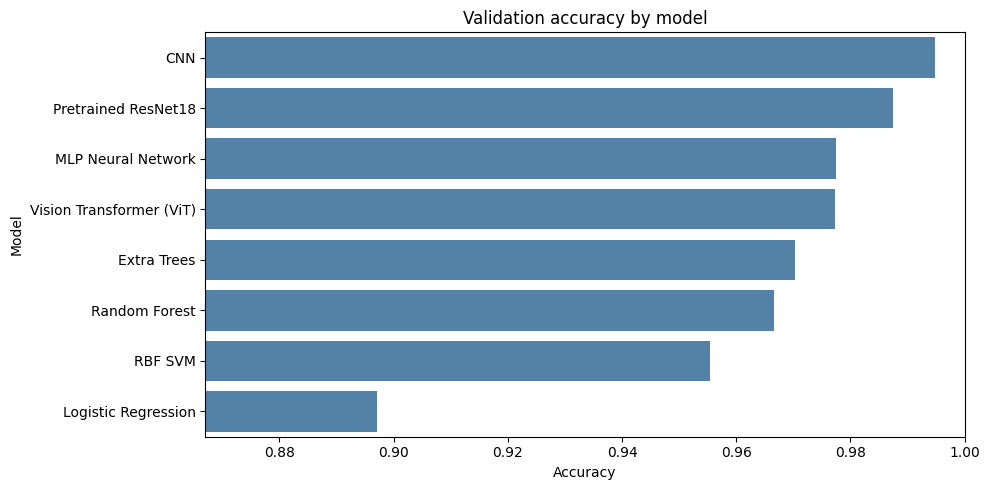

In [20]:
results_df = (
    pd.DataFrame(results)
    .sort_values("Validation Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({"Validation Accuracy": "{:.5%}"}))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df,
    x="Validation Accuracy",
    y="Model",
    color="steelblue"
)
plt.xlim(max(0, results_df["Validation Accuracy"].min() - 0.03), 1.0)
plt.title("Validation accuracy by model")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

# Detailed Evaluation of the Best Validation Model

Best model based on validation accuracy: CNN
              precision    recall  f1-score   support

           0     0.9940    0.9988    0.9964       827
           1     0.9936    0.9968    0.9952       937
           2     0.9964    0.9928    0.9946       835
           3     0.9977    0.9885    0.9931       870
           4     0.9951    0.9975    0.9963       814
           5     0.9934    0.9921    0.9927       759
           6     0.9952    0.9964    0.9958       827
           7     0.9932    0.9966    0.9949       880
           8     0.9951    0.9938    0.9945       813
           9     0.9940    0.9940    0.9940       838

    accuracy                         0.9948      8400
   macro avg     0.9948    0.9947    0.9947      8400
weighted avg     0.9948    0.9948    0.9948      8400



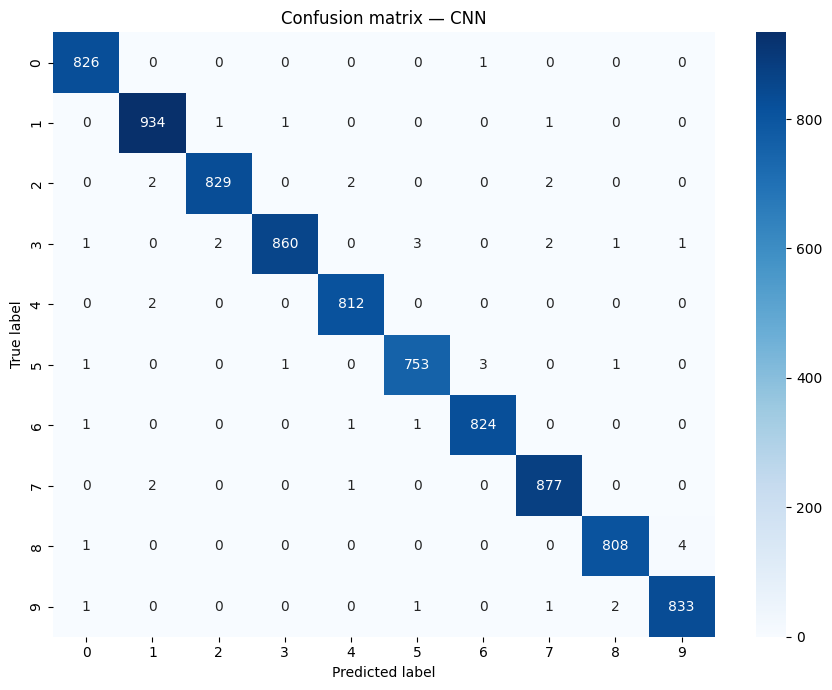

In [21]:
best_model_name = results_df.loc[0, "Model"]
print("Best model based on validation accuracy:", best_model_name)

if best_model_name in ["Pretrained ResNet18", "ResNet18 (unpretrained fallback)"]:
    best_valid_predictions = pred_resnet
elif best_model_name == "Vision Transformer (ViT)":
    best_valid_predictions = pred_vit
elif best_model_name == "CNN":
    best_valid_predictions = pred_cnn
elif best_model_name == "MLP Neural Network":
    best_valid_predictions = pred_mlp
elif best_model_name == "RBF SVM":
    best_valid_predictions = pred_svm
elif best_model_name == "Extra Trees":
    best_valid_predictions = pred_et
elif best_model_name == "Random Forest":
    best_valid_predictions = pred_rf
else:
    best_valid_predictions = pred_log

print(classification_report(y_valid, best_valid_predictions, digits=4))

cm = confusion_matrix(y_valid, best_valid_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion matrix — {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

# Inspect Misclassified Examples

Number of validation errors: 44


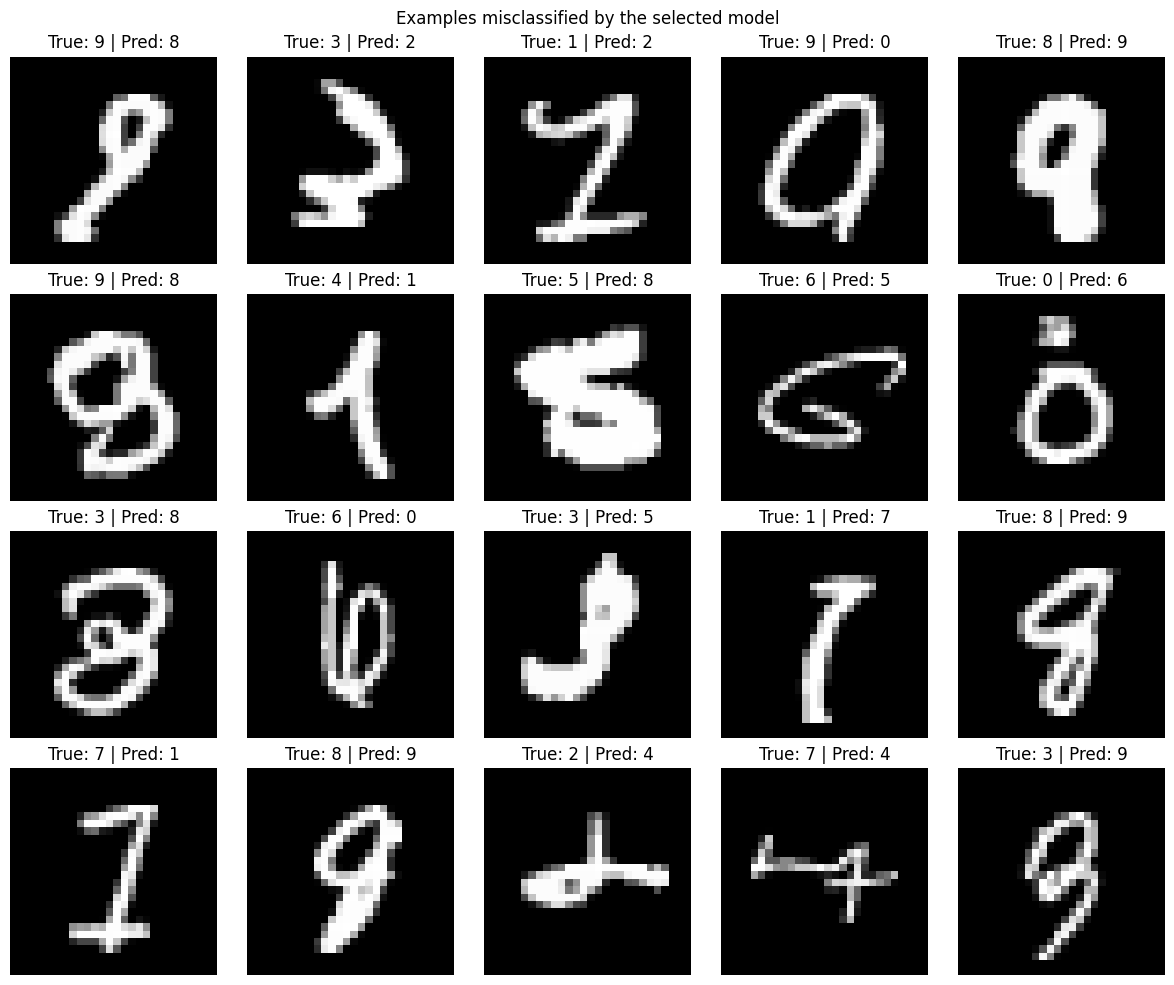

In [22]:
wrong_indices = np.where(best_valid_predictions != y_valid)[0]
print("Number of validation errors:", len(wrong_indices))

if len(wrong_indices) > 0:
    show_n = min(20, len(wrong_indices))
    selected = wrong_indices[:show_n]

    fig, axes = plt.subplots(4, 5, figsize=(12, 10))
    for ax, idx in zip(axes.ravel(), selected):
        ax.imshow(X_valid_raw[idx].reshape(28, 28), cmap="gray")
        ax.set_title(
            f"True: {y_valid[idx]} | Pred: {best_valid_predictions[idx]}"
        )
        ax.axis("off")
    for ax in axes.ravel()[show_n:]:
        ax.axis("off")
    plt.suptitle("Examples misclassified by the selected model")
    plt.tight_layout()
    plt.show()
else:
    print("No validation errors for this model.")

# Final Model and Kaggle Setup Submission

In [23]:

# ============================================================
# FINAL MODEL TRAINING AND TEST PREDICTIONS
# ============================================================

import copy
import gc

# ------------------------------------------------------------
# 1. PREPARE FINAL FEATURES
# ------------------------------------------------------------

X_full_scaled = X_all.astype(np.float32) / 255.0
X_test_scaled = X_test_raw.astype(np.float32) / 255.0

X_full_img = X_full_scaled.reshape(-1, 28, 28, 1)
X_test_img = X_test_scaled.reshape(-1, 28, 28, 1)


# ------------------------------------------------------------
# 2. PREPARE RESNET DATASET
# ------------------------------------------------------------

def prepare_resnet_dataset(x_numpy):

    return torch.as_tensor(
        x_numpy,
        dtype=torch.float32
    ).reshape(-1, 1, 28, 28) / 255.0


# ------------------------------------------------------------
# 3. FULL-DATA TRAINING FUNCTION
# ------------------------------------------------------------

def fit_full_data_without_validation(
    model,
    loader,
    epochs,
    lr,
    batch_transform=None
):

    model.train()

    parameters = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        parameters,
        lr=lr,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0

        for batch in loader:

            # Support TensorDataset with or without labels
            xb, yb = batch[0], batch[1]

            xb = (
                batch_transform(xb)
                if batch_transform is not None
                else xb.to(DEVICE)
            )

            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(xb)

            loss = criterion(logits, yb)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * len(yb)

        print(
            f"Full-data refit epoch "
            f"{epoch + 1}/{epochs} | "
            f"loss {total_loss / len(loader.dataset):.4f}"
        )

    return model


# ============================================================
# 4. RESNET18 FINAL MODEL
# ============================================================

if best_model_name in [
    "Pretrained ResNet18",
    "ResNet18 (unpretrained fallback)"
]:

    print("\nRefitting ResNet18 on all labelled data...")

    X_full_res = prepare_resnet_dataset(X_all)

    X_test_res_final = prepare_resnet_dataset(
        X_test_raw
    )

    full_res_loader = make_loader(
        X_full_res,
        y_all,
        shuffle=True
    )

    test_res_loader_final = make_loader(
        X_test_res_final
    )

    # Start with validation-trained weights
    final_model = copy.deepcopy(
        resnet_model
    ).to(DEVICE)

    # Refit on complete labelled dataset
    final_model = fit_full_data_without_validation(
        final_model,
        full_res_loader,
        epochs=max(3, RESNET_EPOCHS // 2),
        lr=1e-4,
        batch_transform=preprocess_resnet_batch
    )

    # IMPORTANT: Apply the same preprocessing during prediction
    test_probabilities = torch_predict(
        final_model,
        test_res_loader_final,
        batch_transform=preprocess_resnet_batch
    )

    test_predictions = test_probabilities.argmax(axis=1)

    del X_full_res, X_test_res_final
    del full_res_loader, test_res_loader_final

    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ============================================================
# 5. VISION TRANSFORMER FINAL MODEL
# ============================================================

elif best_model_name == "Vision Transformer (ViT)":

    print("\nRefitting ViT on all labelled data...")

    X_full_vit = prepare_vit_images(X_all)

    X_test_vit_final = prepare_vit_images(
        X_test_raw
    )

    full_vit_loader = make_loader(
        X_full_vit,
        y_all,
        shuffle=True
    )

    test_vit_loader_final = make_loader(
        X_test_vit_final
    )

    final_model = copy.deepcopy(
        vit_model
    ).to(DEVICE)

    final_model = fit_full_data_without_validation(
        final_model,
        full_vit_loader,
        epochs=max(5, VIT_EPOCHS // 2),
        lr=2e-4
    )

    test_probabilities = torch_predict(
        final_model,
        test_vit_loader_final
    )

    test_predictions = test_probabilities.argmax(axis=1)

    del X_full_vit, X_test_vit_final
    del full_vit_loader, test_vit_loader_final

    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ============================================================
# 6. CNN FINAL MODEL
# ============================================================

elif best_model_name == "CNN":

    if not TF_AVAILABLE:
        raise RuntimeError(
            "CNN was selected but TensorFlow is unavailable."
        )

    print("\nRefitting CNN on all labelled data...")

    final_model = keras.models.clone_model(
        cnn_model
    )

    final_model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    final_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5
        )
    ]

    final_model.fit(
        X_full_img,
        y_all,
        validation_split=0.08,
        epochs=20,
        batch_size=128,
        callbacks=final_callbacks,
        verbose=1
    )

    test_probabilities = final_model.predict(
        X_test_img,
        verbose=0
    )

    test_predictions = np.argmax(
        test_probabilities,
        axis=1
    )


# ============================================================
# 7. MLP FINAL MODEL
# ============================================================

elif best_model_name == "MLP Neural Network":

    print("\nRefitting MLP on all labelled data...")

    final_model = MLPClassifier(
        hidden_layer_sizes=(512, 256),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=35,
        early_stopping=True,
        validation_fraction=0.12,
        n_iter_no_change=5,
        random_state=SEED,
        verbose=True
    )

    final_model.fit(
        X_full_scaled,
        y_all
    )

    test_predictions = final_model.predict(
        X_test_scaled
    )


# ============================================================
# 8. RBF SVM FINAL MODEL
# ============================================================

elif best_model_name == "RBF SVM":

    print("\nRefitting RBF SVM on all labelled data...")

    final_model = Pipeline([
        ("scaler", StandardScaler()),

        ("model", SVC(
            C=8.0,
            kernel="rbf",
            gamma="scale",
            cache_size=1500
        ))
    ])

    final_model.fit(
        X_full_scaled,
        y_all
    )

    test_predictions = final_model.predict(
        X_test_scaled
    )


# ============================================================
# 9. EXTRA TREES FINAL MODEL
# ============================================================

elif best_model_name == "Extra Trees":

    print("\nRefitting Extra Trees on all labelled data...")

    final_model = ExtraTreesClassifier(
        n_estimators=400,
        max_features="sqrt",
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=SEED
    )

    final_model.fit(
        X_all,
        y_all
    )

    test_predictions = final_model.predict(
        X_test_raw
    )


# ============================================================
# 10. RANDOM FOREST FINAL MODEL
# ============================================================

elif best_model_name == "Random Forest":

    print("\nRefitting Random Forest on all labelled data...")

    final_model = RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=SEED
    )

    final_model.fit(
        X_all,
        y_all
    )

    test_predictions = final_model.predict(
        X_test_raw
    )


# ============================================================
# 11. LOGISTIC REGRESSION FINAL MODEL
# ============================================================

else:

    print("\nRefitting Logistic Regression on all labelled data...")

    final_model = Pipeline([
        ("scaler", StandardScaler()),

        ("model", LogisticRegression(
            max_iter=1200,
            solver="lbfgs",
            C=3.0,
            random_state=SEED
        ))
    ])

    final_model.fit(
        X_full_scaled,
        y_all
    )

    test_predictions = final_model.predict(
        X_test_scaled
    )


# ============================================================
# 12. FINAL PREDICTION CHECKS
# ============================================================

test_predictions = np.asarray(
    test_predictions
).reshape(-1)

assert len(test_predictions) == len(X_test_raw), (
    "Prediction count does not match test dataset size."
)

assert np.issubdtype(
    test_predictions.dtype,
    np.integer
), "Predictions must contain integer class labels."

print("\n====================================")
print("FINAL MODEL:", best_model_name)
print("====================================")

print("Predictions generated:", len(test_predictions))

print(
    "Prediction classes:",
    np.unique(test_predictions)
)

print("\nFinal prediction generation completed successfully.")


Refitting CNN on all labelled data...
Epoch 1/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 60ms/step - accuracy: 0.9393 - loss: 0.2001 - val_accuracy: 0.1077 - val_loss: 5.3172 - learning_rate: 0.0010
Epoch 2/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9795 - loss: 0.0692 - val_accuracy: 0.9714 - val_loss: 0.0914 - learning_rate: 0.0010
Epoch 3/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9844 - loss: 0.0513 - val_accuracy: 0.9872 - val_loss: 0.0337 - learning_rate: 0.0010
Epoch 4/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9877 - loss: 0.0418 - val_accuracy: 0.9887 - val_loss: 0.0327 - learning_rate: 0.0010
Epoch 5/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9889 - loss: 0.0366 - val_accuracy: 0.9890 - val_loss: 0.0314 - learning_rate: 0.0010
Epoch 6/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9896 - loss: 0.0337 - val_accuracy: 0.9872 - val_loss: 0.0369 - learning_rate: 0.0010
Epoch 7/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 3s

## Kaggle submission file

In [24]:
submission = pd.DataFrame({
    "ImageId": np.arange(1, len(test_predictions) + 1),
    "Label": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
display(submission.head())
print("Saved to:", Path("submission.csv").resolve())

Submission shape: (28000, 2)


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,0
4,5,3


Saved to: /content/submission.csv


## Submission Validation Checks

In [25]:
EXPECTED_TEST_ROWS = len(test_df)

assert list(submission.columns) == ["ImageId", "Label"], "Incorrect column names/order."
assert len(submission) == EXPECTED_TEST_ROWS, "Submission row count does not match test.csv."
assert submission["ImageId"].is_unique, "ImageId values must be unique."
assert submission["ImageId"].iloc[0] == 1, "ImageId must start at 1."
assert submission["ImageId"].iloc[-1] == EXPECTED_TEST_ROWS, "Unexpected final ImageId."
assert submission["Label"].notna().all(), "Predictions contain missing values."
assert submission["Label"].between(0, 9).all(), "Labels must be digits 0–9."
assert np.issubdtype(submission["Label"].dtype, np.integer), "Labels must be integers."

print("All submission checks passed.")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Predicted digit counts:")
display(submission["Label"].value_counts().sort_index().to_frame("count"))

All submission checks passed.
Rows: 28000
Columns: ['ImageId', 'Label']
Predicted digit counts:


,count
Label,
0,2766
1,3192
2,2810
3,2789
4,2746
5,2520
6,2750
7,2893
8,2748
